# 10 · Figure style and export

Every visual setting is one named setting of a **style**. Start from a preset and change what you like:

| preset | look |
|---|---|
| `"clean"` (default) | light grid, open box, ticks out, wide |
| `"publication"` | closed box, ticks in on all sides, no grid |
| `"matlab"` | MATLAB colours, square, bold Arial, thick grey box, black tick labels, 1200 dpi tiff (like `separation1.tiff`) |
| `"matplotlib"` | matplotlib's own defaults |

```python
c.plot(style="publication", aspect="square", box_width=2, colors="matlab", line_style=":")
stk.set_style("matlab")                    # default for every later plot
stk.save_style("matlab", "my_style", line_width=2)   # -> my_style.json, use style="my_style.json"
stk.export(ax, "figure2", folder="figures", format="tiff", dpi=1200, color="cmyk")
```

All settings with their meaning: `stk.style.SETTINGS` (printed below).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import spectrum_toolkit as stk
from spectrum_toolkit.style import SETTINGS, PRESETS, PALETTES, SIZES

for name, (default, meaning) in SETTINGS.items():
    print(f'{name:18s} {str(default):28s} {meaning}')

size               screen                       figure size: a name in SIZES or (width, height) in "units"
units              cm                           "cm" or "in" for size
aspect             None                         plot area shape: None (fills the figure), "square", or height/width e.g. 0.75
font               sans-serif                   font name, e.g. "Arial", "Times New Roman"; falls back if not installed
font_size          10                           tick label size in points
font_weight        normal                       "normal" or "bold": all text
label_size         11                           axis label size in points
label_weight       normal                       "normal" or "bold": axis labels
label_color        black                        axis label colour
title_size         11                           title size in points
box                open                         "closed" (all four sides), "open" (left and bottom) or "none"
box_width          0.8     

## 1. Your MATLAB figure (main.m) rebuilt: PCA of CV, MB, RhB and the mixtures

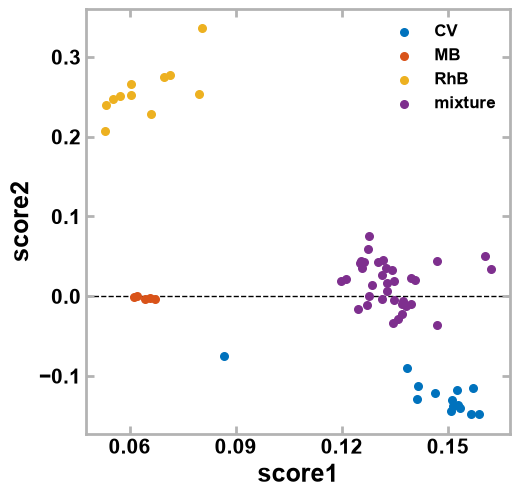

In [2]:
files = ['../data/CV10-4M.xlsx', '../data/MB 10-4M.xlsx', '../data/RhB10-4M.xlsx', '../data/CV+RhB+MB.xlsx']
parts = [stk.load(f, verbose=False) for f in files]
c = stk.combine(*parts, interpolate=True, verbose=False).despike(verbose=False).baseline()

# As in main.m: normalize(data, 'range') per spectrum, then pca with the wavenumber points as observations.
Y = (c.Y - c.Y.min(axis=1, keepdims=True)) / np.ptp(c.Y, axis=1, keepdims=True)
D = Y.T - Y.T.mean(axis=0)
_, _, Vt = np.linalg.svd(D, full_matrices=False)
coeff = Vt.T * np.sign(Vt.T.sum(axis=0))           # same sign convention as MATLAB's pca
groups = sum([[n] * len(p) for n, p in zip(['CV', 'MB', 'RhB', 'mixture'], parts)], [])

ax = stk.scatter(coeff[:, 0], coeff[:, 1], groups, style='matlab', xlabel='score1', ylabel='score2',
                 zero_lines='x', x_tick_step=0.03, x_tick_format='%.2f')

(PCA itself becomes a proper feature later; this is only to show the figure style.)

## 2. The same spectra in each preset

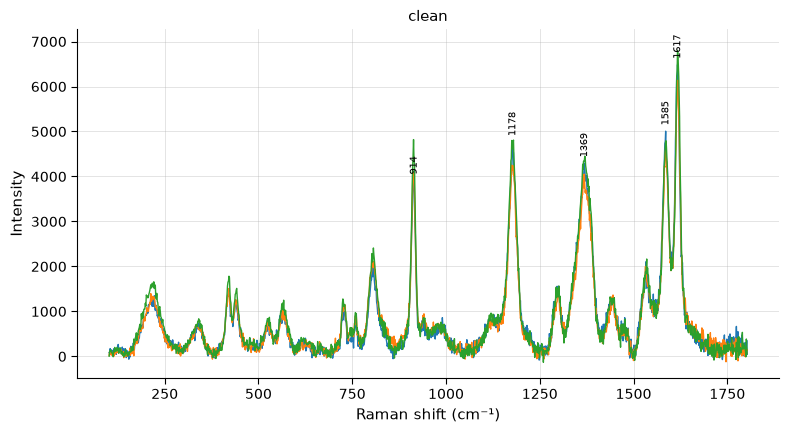

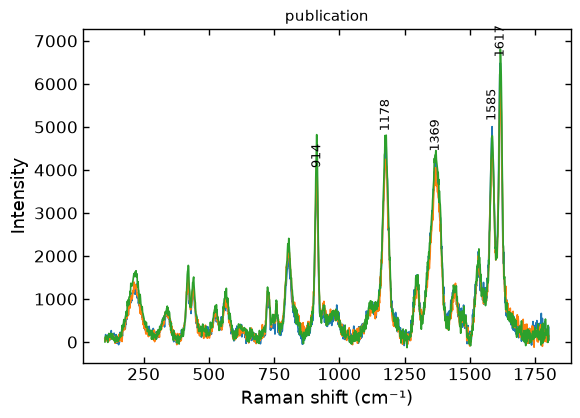

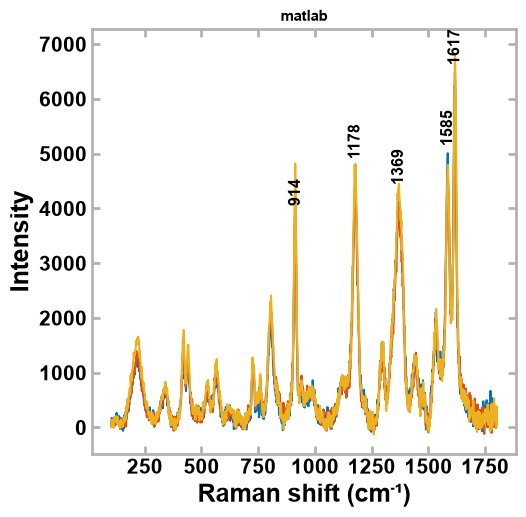

In [3]:
cv = parts[0].despike(verbose=False).baseline()
for preset in ['clean', 'publication', 'matlab']:
    cv.select(0, 1, 2).plot(style=preset, xlabel='Raman shift (cm⁻¹)', title=preset, peaks=5, legend=False)

## 3. Style editor

Change any setting and see the figure update. **Export** saves it with the name, folder, type, DPI and colour mode shown; **Save style** writes your settings to a `.json` file you can reuse with `style="name.json"`.

In [4]:
import ipywidgets as W
from IPython.display import display

data = {'3 CV spectra': cv.select(0, 1, 2), '14 CV spectra': cv, 'CV stack': cv}
c_ = lambda **kw: W.Layout(width='auto', **kw)

w = dict(
    preset=W.Dropdown(options=['clean', 'publication', 'matlab'], value='publication', description='preset'),
    data=W.Dropdown(options=list(data), description='data'),
    size=W.Dropdown(options=list(SIZES) + ['custom'], value='screen', description='size'),
    width=W.FloatText(value=16, description='width cm'), height=W.FloatText(value=11, description='height cm'),
    aspect=W.Dropdown(options=['fill', 'square', '0.5', '0.75'], description='aspect'),
    box=W.Dropdown(options=['closed', 'open', 'none'], value='closed', description='box'),
    box_width=W.FloatSlider(value=1.0, min=0.2, max=4, step=0.1, description='box width'),
    box_color=W.ColorPicker(value='#000000', description='box colour'),
    ticks=W.Dropdown(options=['in', 'out', 'both'], value='in', description='ticks'),
    tick_length=W.FloatSlider(value=4, min=0, max=12, step=0.5, description='tick length'),
    tick_sides=W.SelectMultiple(options=['bottom', 'top', 'left', 'right'], value=['bottom', 'top', 'left', 'right'], description='tick sides'),
    tick_label_sides=W.SelectMultiple(options=['bottom', 'top', 'left', 'right'], value=['bottom', 'left'], description='label sides'),
    tick_label_color=W.ColorPicker(value='#000000', description='label colour'),
    minor_ticks=W.Checkbox(value=False, description='minor ticks'),
    font=W.Dropdown(options=['sans-serif', 'Arial', 'Helvetica', 'Times New Roman', 'DejaVu Sans'], description='font'),
    font_size=W.IntSlider(value=12, min=6, max=24, description='tick label size'),
    label_size=W.IntSlider(value=13, min=6, max=28, description='axis label size'),
    font_weight=W.Dropdown(options=['normal', 'bold'], description='weight'),
    colors=W.Dropdown(options=list(PALETTES), value='matlab', description='colours'),
    line_width=W.FloatSlider(value=1.2, min=0.2, max=4, step=0.1, description='line width'),
    line_style=W.Dropdown(options=[('solid', '-'), ('dashed', '--'), ('dotted', ':'), ('dash-dot', '-.'), ('markers only', 'none')], description='line style'),
    grid=W.Checkbox(value=False, description='grid'),
    legend=W.Dropdown(options=[('auto', 'auto'), ('on', True), ('off', False)], description='legend'),
    legend_location=W.Dropdown(options=['best', 'upper right', 'upper left', 'outside'], description='legend at'),
    peaks=W.IntSlider(value=0, min=0, max=10, description='label peaks'),
)
out = W.Output()

def settings():
    s = {k: w[k].value for k in ['box', 'box_width', 'box_color', 'ticks', 'tick_length', 'tick_label_color',
                                 'minor_ticks', 'font', 'font_size', 'label_size', 'font_weight', 'colors',
                                 'line_width', 'line_style', 'grid', 'legend', 'legend_location']}
    s['label_weight'] = s['font_weight']
    s['tick_sides'], s['tick_label_sides'] = tuple(w['tick_sides'].value), tuple(w['tick_label_sides'].value)
    s['size'] = (w['width'].value, w['height'].value) if w['size'].value == 'custom' else w['size'].value
    s['aspect'] = None if w['aspect'].value == 'fill' else ('square' if w['aspect'].value == 'square' else float(w['aspect'].value))
    return s

state = {}
def redraw(*_):
    with out:
        out.clear_output(wait=True)
        try:
            kind = 'stack' if w['data'].value == 'CV stack' else 'lines'
            state['ax'] = data[w['data'].value].plot(kind, style=w['preset'].value, xlabel='Raman shift (cm⁻¹)',
                                                     peaks=w['peaks'].value or None, **settings())
            plt.show()
        except Exception as e:
            print('Error:', e)

for x in w.values():
    x.observe(redraw, names='value')

name, folder = W.Text(value='figure', description='name'), W.Text(value='figures', description='folder')
fmt = W.Dropdown(options=['png', 'tiff', 'jpg', 'pdf', 'svg', 'eps'], value='tiff', description='type')
dpi = W.Dropdown(options=[150, 300, 600, 1200], value=600, description='dpi')
mode = W.Dropdown(options=['rgb', 'cmyk'], description='colour')
transparent = W.Checkbox(value=False, description='transparent')
msg = W.Output()
def do_export(_):
    with msg:
        msg.clear_output()
        try:
            print('saved', stk.export(state['ax'], name.value, folder=folder.value, format=fmt.value, dpi=dpi.value,
                                      color=mode.value, transparent=transparent.value))
        except Exception as e:
            print('Error:', e)
def do_save_style(_):
    with msg:
        msg.clear_output()
        print('saved', stk.save_style(w['preset'].value, name.value + '_style', **settings()))
b1, b2 = W.Button(description='Export figure'), W.Button(description='Save style')
b1.on_click(do_export); b2.on_click(do_save_style)

tabs = W.Tab(children=[
    W.VBox([w[k] for k in ['preset', 'data', 'size', 'width', 'height', 'aspect']]),
    W.VBox([w[k] for k in ['box', 'box_width', 'box_color', 'ticks', 'tick_length', 'tick_sides', 'tick_label_sides', 'tick_label_color', 'minor_ticks']]),
    W.VBox([w[k] for k in ['font', 'font_size', 'label_size', 'font_weight']]),
    W.VBox([w[k] for k in ['colors', 'line_width', 'line_style', 'peaks']]),
    W.VBox([w[k] for k in ['grid', 'legend', 'legend_location']]),
    W.VBox([name, folder, fmt, dpi, mode, transparent, W.HBox([b1, b2]), msg]),
])
for i, t in enumerate(['Figure', 'Box & ticks', 'Text', 'Lines', 'Grid & legend', 'Export']):
    tabs.set_title(i, t)
display(tabs, out)
redraw()

Output()

## 4. In code

Everything the editor does is one call; `stk.export` gives full control when saving.

In [ ]:
ax = cv.select(0, 1, 2).plot(style='publication', size=(12, 9), aspect='square', box_width=1.5,
                             colors='colorblind', line_width=1.5, ticks='in', minor_ticks=True,
                             marks={1585: 'C=C', 1620: 'ring'}, region=(1300, 1700),
                             xlabel='Raman shift (cm⁻¹)', legend_location='upper left')
# stk.export(ax, 'cv_zoom', folder='figures', format='tiff', dpi=1200, color='cmyk')